# Gláucio Soares da Silva

**Aplicação do Algoritmo Dijkstra para otimização de rotas com o título de  Caminhos Mínimos, Cidades Eficientes: O Poder do Algoritmo de Dijkstra**


1 - Importação das Dependências

In [ ]:
import heapq
import networkx as nx
import matplotlib.pyplot as plt

2 - Definição do grafo do estudo

In [ ]:
grafo = {
    'Casa': {'A': 5, 'B': 2},
    'A': {'Casa': 5, 'B': 1, 'Terminal': 6},
    'B': {'Casa': 2, 'A': 1, 'Terminal': 4, 'Mercado': 7},
    'Terminal': {'A': 6, 'B': 4, 'Mercado': 2, 'Faculdade': 3},
    'Mercado': {'B': 7, 'Terminal': 2, 'Faculdade': 2},
    'Faculdade': {'Terminal': 3, 'Mercado': 2}
}

3 - Algoritmo de Dijkstra

In [ ]:
def dijkstra(grafo, inicio):
    distancias = {no: float('inf') for no in grafo}
    predecessores = {no: None for no in grafo}
    distancias[inicio] = 0

    fila = [(0, inicio)]

    while fila:
        dist_atual, no_atual = heapq.heappop(fila)

        if dist_atual > distancias[no_atual]:
            continue

        for vizinho, peso in grafo[no_atual].items():
            nova_distancia = dist_atual + peso

            if nova_distancia < distancias[vizinho]:
                distancias[vizinho] = nova_distancia
                predecessores[vizinho] = no_atual
                heapq.heappush(fila, (nova_distancia, vizinho))

    return distancias, predecessores

4 - Função para reconstruir o caminho mínimo

In [ ]:
def reconstruir_caminho(predecessores, inicio, fim):
    caminho = []
    atual = fim

    while atual is not None:
        caminho.append(atual)
        atual = predecessores[atual]

    caminho.reverse()

    if caminho and caminho[0] == inicio:
        return caminho
    return []

5 - Visualização do grafo geral

In [ ]:
def visualizar_grafo_geral(grafo):
    G = nx.DiGraph()

    for origem, vizinhos in grafo.items():
        for destino, peso in vizinhos.items():
            G.add_edge(origem, destino, weight=peso)

    # posições parecidas com o layout da imagem
    pos = {
        'Casa': (-2.0, 0.2),
        'A': (-0.3, 0.8),
        'B': (-0.8, -0.8),
        'Terminal': (1.0, -0.5),
        'Mercado': (1.4, -0.9),
        'Faculdade': (1.8, 0.7)
    }

    node_colors = ['darkred', '#1d2a44', '#1d2a44', 'slategray', 'slategray', '#11a36a']

    plt.figure(figsize=(10, 7))

    nx.draw_networkx_nodes(
        G, pos,
        node_color=node_colors,
        node_size=2200
    )

    nx.draw_networkx_labels(
        G, pos,
        font_size=12,
        font_color='white',
        font_weight='bold'
    )

    nx.draw_networkx_edges(
        G, pos,
        arrows=True,
        arrowstyle='-|>',
        arrowsize=20,
        width=2,
        connectionstyle='arc3,rad=0.05'
    )

    edge_labels = nx.get_edge_attributes(G, 'weight')
    nx.draw_networkx_edge_labels(
        G, pos,
        edge_labels=edge_labels,
        font_size=11
    )

    plt.title("Modelo Geral do Grafo", fontsize=16, fontweight='bold')
    plt.axis('off')
    plt.show()

6 - Tabela dos dados utilizados

In [ ]:
for origem, vizinhos in grafo.items():
    for destino, peso in vizinhos.items():
        print(f"{origem} -> {destino} = {peso}")

Casa -> A = 5
Casa -> B = 2
A -> Casa = 5
A -> B = 1
A -> Terminal = 6
B -> Casa = 2
B -> A = 1
B -> Terminal = 4
B -> Mercado = 7
Terminal -> A = 6
Terminal -> B = 4
Terminal -> Mercado = 2
Terminal -> Faculdade = 3
Mercado -> B = 7
Mercado -> Terminal = 2
Mercado -> Faculdade = 2
Faculdade -> Terminal = 3
Faculdade -> Mercado = 2


7 - Modelo geral antes da solução ótima

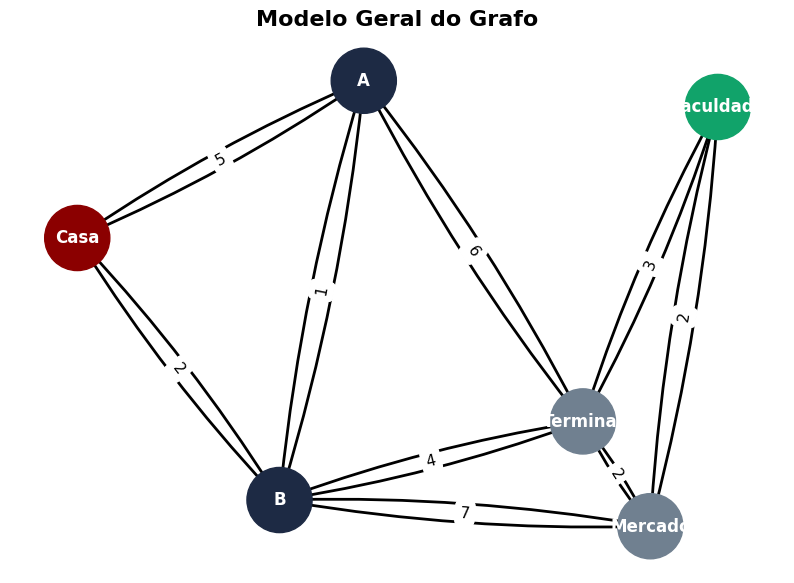

In [ ]:
visualizar_grafo_geral(grafo)

8 - Execução do algoritmo

In [ ]:
inicio = 'Casa'
fim = 'Faculdade'

distancias, predecessores = dijkstra(grafo, inicio)
caminho = reconstruir_caminho(predecessores, inicio, fim)

print("Distâncias mínimas:")
print(distancias)

print("\nCaminho mínimo encontrado:")
print(" -> ".join(caminho))

print(f"\nCusto total: {distancias[fim]}")

Distâncias mínimas:
{'Casa': 0, 'A': 3, 'B': 2, 'Terminal': 6, 'Mercado': 8, 'Faculdade': 9}

Caminho mínimo encontrado:
Casa -> B -> Terminal -> Faculdade

Custo total: 9


9 - Visualização da solução ótima

In [ ]:
def visualizar_solucao_otima(grafo, caminho):
    G = nx.DiGraph()

    for origem, vizinhos in grafo.items():
        for destino, peso in vizinhos.items():
            G.add_edge(origem, destino, weight=peso)

    pos = {
        'Casa': (-2.0, 0.2),
        'A': (-0.3, 0.8),
        'B': (-0.8, -0.8),
        'Terminal': (1.0, -0.5),
        'Mercado': (1.4, -0.9),
        'Faculdade': (1.8, 0.7)
    }

    node_colors = ['darkred', '#1d2a44', '#1d2a44', 'slategray', 'slategray', '#11a36a']

    plt.figure(figsize=(10, 7))

    nx.draw_networkx_nodes(
        G, pos,
        node_color=node_colors,
        node_size=2200
    )

    nx.draw_networkx_labels(
        G, pos,
        font_size=12,
        font_color='white',
        font_weight='bold'
    )

    # arestas normais
    nx.draw_networkx_edges(
        G, pos,
        arrows=True,
        arrowstyle='-|>',
        arrowsize=20,
        width=1.8,
        alpha=0.35,
        connectionstyle='arc3,rad=0.05'
    )

    # destacar caminho ótimo
    arestas_caminho = list(zip(caminho, caminho[1:]))

    nx.draw_networkx_edges(
        G, pos,
        edgelist=arestas_caminho,
        arrows=True,
        arrowstyle='-|>',
        arrowsize=24,
        width=4,
        edge_color='red',
        connectionstyle='arc3,rad=0.05'
    )

    edge_labels = nx.get_edge_attributes(G, 'weight')
    nx.draw_networkx_edge_labels(
        G, pos,
        edge_labels=edge_labels,
        font_size=11
    )

    plt.title("Solução Ótima no Grafo", fontsize=16, fontweight='bold')
    plt.axis('off')
    plt.show()


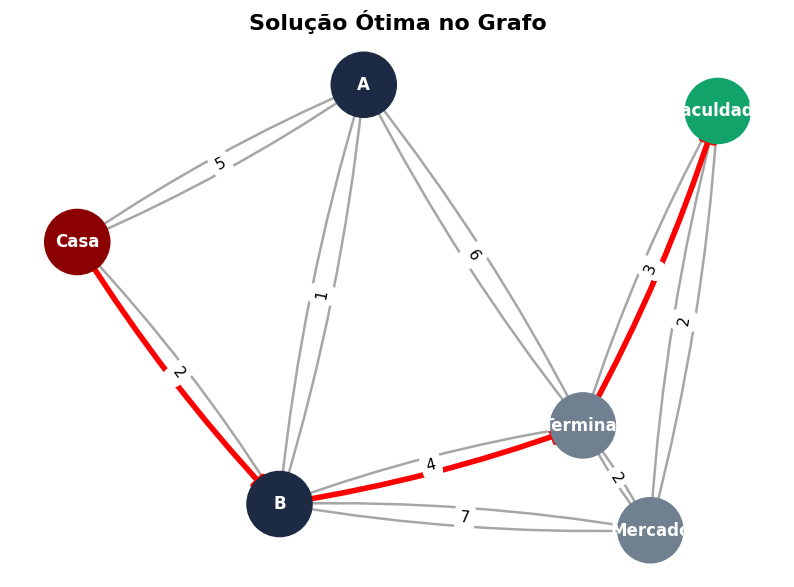

In [ ]:
visualizar_solucao_otima(grafo, caminho)

8 - Conclusão

A execução do algoritmo de Dijkstra permitiu calcular corretamente as menores distâncias a partir do nó A e identificar o caminho mínimo até D.

O menor caminho encontrado foi: A → B → C → D, mostrando que o algoritmo escolhe a rota com menor custo total, mesmo quando há caminhos mais curtos em número de etapas, porém com maior peso.

Assim, o algoritmo se mostra eficiente para problemas de caminho mínimo em grafos com pesos não negativos